In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [18]:
# Set style for EDA plots
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

In [19]:
# Load the scraped dataset
df = pd.read_csv("books_dataset.csv")
print(f"Dataset Shape: {df.shape}")
df.head(3)

Dataset Shape: (1000, 12)


,Book_ID,Title,Description,Category_Label,Image_Local_Path,UPC,Price_Excl_Tax,Price_Incl_Tax,Tax,Availability,Number_of_Reviews,Source_URL
0,1,A Light in the Attic,It's hard to imagine a world without A Light i...,Poetry,images/1.jpg,a897fe39b1053632,Â£51.77,Â£51.77,Â£0.00,In stock (22 available),0,https://books.toscrape.com/catalogue/a-light-i...
1,2,Tipping the Velvet,"""Erotic and absorbing...Written with starling ...",Historical Fiction,images/2.jpg,90fa61229261140a,Â£53.74,Â£53.74,Â£0.00,In stock (20 available),0,https://books.toscrape.com/catalogue/tipping-t...
2,3,Soumission,"Dans une France assez proche de la nÃ´tre, un ...",Fiction,images/3.jpg,6957f44c3847a760,Â£50.10,Â£50.10,Â£0.00,In stock (20 available),0,https://books.toscrape.com/catalogue/soumissio...


In [20]:
# List of irrelevant columns to drop
irrelevant_cols = [
    'UPC', 'Price_Excl_Tax', 'Price_Incl_Tax', 
    'Tax', 'Availability', 'Number_of_Reviews', 'Source_URL'
]

# Drop useless columns
df = df.drop(columns=[col for col in irrelevant_cols if col in df.columns])
df[:5]

,Book_ID,Title,Description,Category_Label,Image_Local_Path
0,1,A Light in the Attic,It's hard to imagine a world without A Light i...,Poetry,images/1.jpg
1,2,Tipping the Velvet,"""Erotic and absorbing...Written with starling ...",Historical Fiction,images/2.jpg
2,3,Soumission,"Dans une France assez proche de la nÃ´tre, un ...",Fiction,images/3.jpg
3,4,Sharp Objects,"WICKED above her hipbone, GIRL across her hear...",Mystery,images/4.jpg
4,5,Sapiens: A Brief History of Humankind,From a renowned historian comes a groundbreaki...,History,images/5.jpg


In [21]:
# Handle missing descriptions if any exist
df['Description'] = df['Description'].fillna('')

print("Cleaned Columns:", df.columns.tolist())
print(f"Missing values check:\n{df.isnull().sum()}")

Cleaned Columns: ['Book_ID', 'Title', 'Description', 'Category_Label', 'Image_Local_Path']
Missing values check:
Book_ID             0
Title               0
Description         0
Category_Label      0
Image_Local_Path    0
dtype: int64


In [22]:
# Map books categories into Fiction vs Non-Fiction
non_fiction_genres = {
    'Travel', 'Religion', 'Nonfiction', 'Music', 'Philosophy', 
    'Sports and Games', 'Art', 'Psychology', 'Autobiography', 
    'Parenting', 'History', 'Food and Drink', 'Business', 
    'Biography', 'Spirituality', 'Academic', 'Self Help', 
    'Health', 'Politics', 'Cultural'
}

def categorize_book(cat):
    if cat in non_fiction_genres:
        return 0  # Non-Fiction
    return 1      # Fiction

df['Is_Fiction'] = df['Category_Label'].apply(categorize_book)
df['Target_Name'] = df['Is_Fiction'].map({1: 'Fiction', 0: 'Non-Fiction'})

print(f"Class Distribution:\n{df['Target_Name'].value_counts()}")
df[:5]

Class Distribution:
Target_Name
Fiction        733
Non-Fiction    267
Name: count, dtype: int64


,Book_ID,Title,Description,Category_Label,Image_Local_Path,Is_Fiction,Target_Name
0,1,A Light in the Attic,It's hard to imagine a world without A Light i...,Poetry,images/1.jpg,1,Fiction
1,2,Tipping the Velvet,"""Erotic and absorbing...Written with starling ...",Historical Fiction,images/2.jpg,1,Fiction
2,3,Soumission,"Dans une France assez proche de la nÃ´tre, un ...",Fiction,images/3.jpg,1,Fiction
3,4,Sharp Objects,"WICKED above her hipbone, GIRL across her hear...",Mystery,images/4.jpg,1,Fiction
4,5,Sapiens: A Brief History of Humankind,From a renowned historian comes a groundbreaki...,History,images/5.jpg,0,Non-Fiction


In [23]:
# 1. Title character length
df['title_char_len'] = df['Title'].astype(str).apply(len)

# 2. Title word count
df['title_word_count'] = df['Title'].astype(str).apply(lambda x: len(x.split()))

# 3. Colon indicator (Non-fiction heavily relies on colons for subtitles)
df['has_subtitle_colon'] = df['Title'].astype(str).apply(lambda x: 1 if ':' in x else 0)

# 4. Description length & word count (for baseline comparison)
df['desc_char_len'] = df['Description'].apply(len)
df['desc_word_count'] = df['Description'].apply(lambda x: len(x.split()))

# Display engineered dataset preview
df[['Title', 'Target_Name', 'title_char_len', 'title_word_count', 'has_subtitle_colon']].head()

,Title,Target_Name,title_char_len,title_word_count,has_subtitle_colon
0,A Light in the Attic,Fiction,20,5,0
1,Tipping the Velvet,Fiction,18,3,0
2,Soumission,Fiction,10,1,0
3,Sharp Objects,Fiction,13,2,0
4,Sapiens: A Brief History of Humankind,Non-Fiction,37,6,1


In [24]:
# Group original Category_Label under Target_Name and count occurrences
category_breakdown = (
    df.groupby(['Target_Name', 'Category_Label'])
    .size()
    .reset_index(name='Count')
    .sort_values(by=['Target_Name', 'Count'], ascending=[True, False])
)

# Display Fiction categories
print("=== FICTION CATEGORIES ===")
display(category_breakdown[category_breakdown['Target_Name'] == 'Fiction'].reset_index(drop=True))

print("\n=== NON-FICTION CATEGORIES ===")
display(category_breakdown[category_breakdown['Target_Name'] == 'Non-Fiction'].reset_index(drop=True))

=== FICTION CATEGORIES ===


,Target_Name,Category_Label,Count
0,Fiction,Default,152
1,Fiction,Sequential Art,75
2,Fiction,Add a comment,67
3,Fiction,Fiction,65
4,Fiction,Young Adult,54
5,Fiction,Fantasy,48
6,Fiction,Romance,35
7,Fiction,Mystery,32
8,Fiction,Childrens,29
9,Fiction,Historical Fiction,26



=== NON-FICTION CATEGORIES ===


,Target_Name,Category_Label,Count
0,Non-Fiction,Nonfiction,110
1,Non-Fiction,Food and Drink,30
2,Non-Fiction,History,18
3,Non-Fiction,Music,13
4,Non-Fiction,Business,12
5,Non-Fiction,Philosophy,11
6,Non-Fiction,Travel,11
7,Non-Fiction,Autobiography,9
8,Non-Fiction,Art,8
9,Non-Fiction,Psychology,7


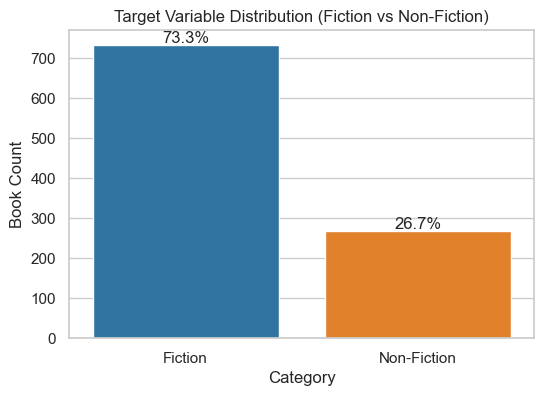

In [25]:
# Visualizing Class Imbalance
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x='Target_Name', palette=['#1f77b4', '#ff7f0e'], ax=ax)
plt.title('Target Variable Distribution (Fiction vs Non-Fiction)')
plt.xlabel('Category')
plt.ylabel('Book Count')

# Show percentages on top of bars
total = len(df)
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.1f}%'
    ax.annotate(percentage, (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')

plt.show()

In [26]:
# 1. Remove the noisy/mixed categories entirely
categories_to_drop = ['Default', 'Add a comment']
df = df[~df['Category_Label'].isin(categories_to_drop)].copy()

# 2. Updated Non-Fiction List (Adding the ones that slipped through)
updated_non_fiction_genres = {
    'Travel', 'Religion', 'Nonfiction', 'Music', 'Philosophy', 
    'Sports and Games', 'Art', 'Psychology', 'Autobiography', 
    'Parenting', 'History', 'Food and Drink', 'Business', 
    'Biography', 'Spirituality', 'Academic', 'Self Help', 
    'Health', 'Politics', 'Cultural', 
    'Science', 'Christian', 'Historical', 'Crime'  # <-- Added corrections here
}

# 3. Re-map the target variable
def categorize_book_fixed(cat):
    if cat in updated_non_fiction_genres:
        return 0  # Non-Fiction
    return 1      # Fiction

df['Is_Fiction'] = df['Category_Label'].apply(categorize_book_fixed)
df['Target_Name'] = df['Is_Fiction'].map({1: 'Fiction', 0: 'Non-Fiction'})

# 4. Check our new, clean class distribution
print("Cleaned Dataset Shape:", df.shape)
print(f"\nNew Class Distribution:\n{df['Target_Name'].value_counts()}")
print(f"\nNew Class Percentages:\n{df['Target_Name'].value_counts(normalize=True) * 100}")
category_breakdown = (
    df.groupby(['Target_Name', 'Category_Label'])
    .size()
    .reset_index(name='Count')
    .sort_values(by=['Target_Name', 'Count'], ascending=[True, False])
)

# Display Fiction categories
print("=== FICTION CATEGORIES ===")
display(category_breakdown[category_breakdown['Target_Name'] == 'Fiction'].reset_index(drop=True))

print("\n=== NON-FICTION CATEGORIES ===")
display(category_breakdown[category_breakdown['Target_Name'] == 'Non-Fiction'].reset_index(drop=True))

Cleaned Dataset Shape: (781, 12)

New Class Distribution:
Target_Name
Fiction        494
Non-Fiction    287
Name: count, dtype: int64

New Class Percentages:
Target_Name
Fiction        63.252241
Non-Fiction    36.747759
Name: proportion, dtype: float64
=== FICTION CATEGORIES ===


,Target_Name,Category_Label,Count
0,Fiction,Sequential Art,75
1,Fiction,Fiction,65
2,Fiction,Young Adult,54
3,Fiction,Fantasy,48
4,Fiction,Romance,35
5,Fiction,Mystery,32
6,Fiction,Childrens,29
7,Fiction,Historical Fiction,26
8,Fiction,Classics,19
9,Fiction,Poetry,19



=== NON-FICTION CATEGORIES ===


,Target_Name,Category_Label,Count
0,Non-Fiction,Nonfiction,110
1,Non-Fiction,Food and Drink,30
2,Non-Fiction,History,18
3,Non-Fiction,Science,14
4,Non-Fiction,Music,13
5,Non-Fiction,Business,12
6,Non-Fiction,Philosophy,11
7,Non-Fiction,Travel,11
8,Non-Fiction,Autobiography,9
9,Non-Fiction,Art,8


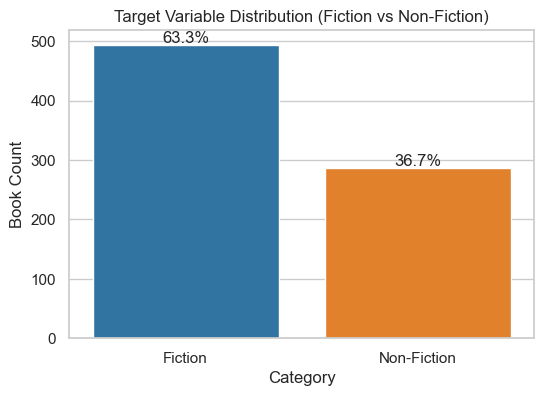

In [27]:
# Visualizing Class Imbalance
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x='Target_Name', palette=['#1f77b4', '#ff7f0e'], ax=ax)
plt.title('Target Variable Distribution (Fiction vs Non-Fiction)')
plt.xlabel('Category')
plt.ylabel('Book Count')

# Show percentages on top of bars
total = len(df)
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.1f}%'
    ax.annotate(percentage, (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')

plt.show()

In [28]:
# Group by category and inspect statistical metrics for our engineered features
feature_stats = df.groupby('Target_Name')[
    ['title_char_len', 'title_word_count', 'has_subtitle_colon', 'desc_word_count']
].agg(['mean', 'median', 'std']).round(2)

feature_stats

title_char_len               title_word_count               \
                      mean median    std             mean median   std   
Target_Name                                                              
Fiction              31.90   30.0  18.95             5.56    5.0  3.20   
Non-Fiction          53.95   52.0  30.80             9.14    9.0  4.87   

            has_subtitle_colon              desc_word_count                 
                          mean median   std            mean median     std  
Target_Name                                                                 
Fiction                   0.13    0.0  0.34          215.01  212.0   78.42  
Non-Fiction               0.66    1.0  0.48          272.96  261.0  120.68